# Echofield
NASA Space Apps Challenge 2026 · Dancing with the SARs · Team Waselah

Tracking center-pivot farms in Al Jouf, Saudi Arabia, with NISAR L-band radar (June to October 2026).



## 1. Setup and login

In [1]:
!pip install -q earthaccess pyproj scikit-image

import os, time, glob, zipfile
import numpy as np
import h5py
import earthaccess
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pyproj import Transformer
from scipy.ndimage import uniform_filter
from scipy import ndimage as ndi

earthaccess.login()
fs = earthaccess.get_fsspec_https_session()
print("ready")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.5 requires fsspec[http]<=2026.2.0,>=2023.1.0, but you have fsspec 2026.9.0 which is incompatible.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2026.9.0 which is incompatible.
Enter your Earthdata Login username: waselah
Enter your Earthdata password: ··········
ready


## 2. Study area and data loader


In [2]:
FARM_LON, FARM_LAT = 38.46, 30.14   # Basaita farms, Al Jouf
HALF = 500                           # half-window in pixels

def load_crop(url):
    t0 = time.time()
    with fs.open(url, mode="rb", cache_type="blockcache", block_size=8*1024*1024) as fobj:
        with h5py.File(fobj, "r") as f:
            grp = f["science/LSAR/GCOV/grids/frequencyA"]
            if "HVHV" not in grp or "HHHH" not in grp:
                print("skipped (missing HH or HV)")
                return None
            proj = grp["projection"]
            epsg = int(proj.attrs.get("epsg_code", proj[()]))
            x = grp["xCoordinates"][:]
            y = grp["yCoordinates"][:]
            spacing = (float(grp["xCoordinateSpacing"][()]), float(grp["yCoordinateSpacing"][()]))
            t = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
            fx, fy = t.transform(FARM_LON, FARM_LAT)
            col = int(np.argmin(np.abs(x - fx)))
            row = int(np.argmin(np.abs(y - fy)))
            win = (slice(row-HALF, row+HALF), slice(col-HALF, col+HALF))
            hh = grp["HHHH"][win]
            hv = grp["HVHV"][win]
    print(f"loaded in {time.time()-t0:.0f} s  (EPSG {epsg}, pixel spacing {spacing})")
    return hh, hv

## 3. Find every NISAR pass over the farms (same track, frame and direction)

In [3]:
results = earthaccess.search_data(
    short_name="NISAR_L2_GCOV_PROVISIONAL_V1",
    bounding_box=(38.4, 30.1, 38.5, 30.2),
    temporal=("2026-06-17", "2026-11-14"),
)

urls = {}
for r in results:
    for link in r.data_links():
        if link.endswith(".h5") and "_071_A_017_" in link:
            date = link.split("_A_2026")[1][:4]
            urls["2026-" + date[:2] + "-" + date[2:]] = link

for d in sorted(urls):
    print(d)
print(len(urls), "dates found")

2026-06-19
2026-07-01
2026-07-13
2026-07-25
2026-08-18
2026-08-30
2026-09-11
2026-09-23
2026-10-05
2026-10-17
10 dates found


## 4. Load all dates (cached after the first run)

In [4]:
cache = "/content/echofield_crops.npz"
data = {}

if os.path.exists(cache):
    z = np.load(cache)
    for key in z.files:
        d, ch = key.rsplit("_", 1)
        data.setdefault(d, {})[ch] = z[key]
    print(len(data), "dates loaded from cache")
else:
    for d in sorted(urls):
        print(d, end=" ... ")
        try:
            out = load_crop(urls[d])
            if out is not None:
                data[d] = {"hh": out[0], "hv": out[1]}
        except Exception as e:
            print("FAILED:", e)
    np.savez_compressed(cache, **{f"{d}_{k}": v for d in data for k, v in data[d].items()})
    print(len(data), "dates loaded and saved")

dates = sorted(data)
px_km2 = (20 * 20) / 1e6   # pixel area, from the 20 m grid spacing printed above
print(dates)

2026-06-19 ... loaded in 19 s  (EPSG 32637, pixel spacing (20.0, -20.0))
2026-07-01 ... loaded in 17 s  (EPSG 32637, pixel spacing (20.0, -20.0))
2026-07-13 ... loaded in 19 s  (EPSG 32637, pixel spacing (20.0, -20.0))
2026-07-25 ... loaded in 22 s  (EPSG 32637, pixel spacing (20.0, -20.0))
2026-08-18 ... loaded in 20 s  (EPSG 32637, pixel spacing (20.0, -20.0))
2026-08-30 ... loaded in 18 s  (EPSG 32637, pixel spacing (20.0, -20.0))
2026-09-11 ... loaded in 18 s  (EPSG 32637, pixel spacing (20.0, -20.0))
2026-09-23 ... skipped (missing HH or HV)
2026-10-05 ... loaded in 18 s  (EPSG 32637, pixel spacing (20.0, -20.0))
2026-10-17 ... loaded in 20 s  (EPSG 32637, pixel spacing (20.0, -20.0))
9 dates loaded and saved
['2026-06-19', '2026-07-01', '2026-07-13', '2026-07-25', '2026-08-18', '2026-08-30', '2026-09-11', '2026-10-05', '2026-10-17']


## 5. Change map, June 19 to October 17


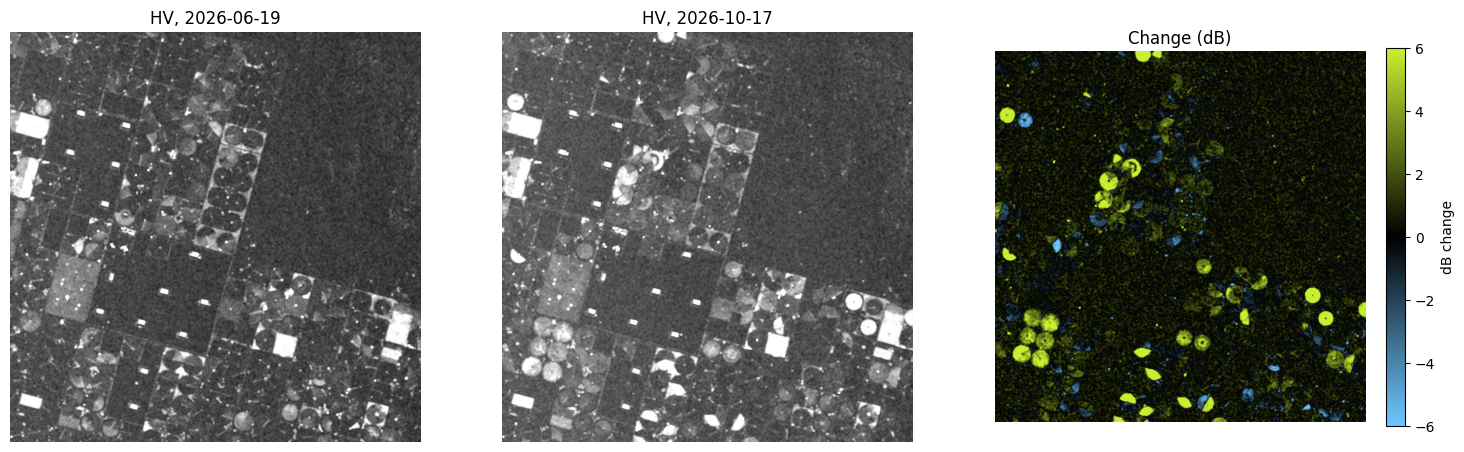

In [5]:
def to_db(p, size=5):
    p = uniform_filter(p.astype("float64"), size=size)
    return 10 * np.log10(np.clip(p, 1e-6, None))

d1, d2 = dates[0], dates[-1]
a = to_db(data[d1]["hv"])
b = to_db(data[d2]["hv"])
change = b - a

echo = LinearSegmentedColormap.from_list("echo", ["#6EC6FF", "#000000", "#C8F031"])

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(a, cmap="gray", vmin=-26, vmax=-16); ax[0].set_title("HV, " + d1)
ax[1].imshow(b, cmap="gray", vmin=-26, vmax=-16); ax[1].set_title("HV, " + d2)
im = ax[2].imshow(change, cmap=echo, vmin=-6, vmax=6); ax[2].set_title("Change (dB)")
plt.colorbar(im, ax=ax[2], fraction=0.046, label="dB change")
for x in ax: x.axis("off")
plt.savefig("/content/change_map.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Noise ruler: empty desert sets the change threshold

In [6]:
DESERT = (slice(50, 350), slice(650, 950))   # empty desert, top right of window

desert = change[DESERT]
bias = desert.mean()
noise = desert.std()
thr = 3 * noise

corrected = change - bias
gain = corrected > thr
loss = corrected < -thr

print(f"desert bias: {bias:.2f} dB   noise: {noise:.2f} dB   threshold: {thr:.2f} dB")
print(f"vegetation gained: {gain.sum() * px_km2:.1f} km²")
print(f"vegetation lost:   {loss.sum() * px_km2:.1f} km²")

desert bias: 0.36 dB   noise: 0.50 dB   threshold: 1.51 dB
vegetation gained: 24.6 km²
vegetation lost:   13.3 km²


## 7. Changed fields and two example fields through the season

33 gained fields, 19 lost fields


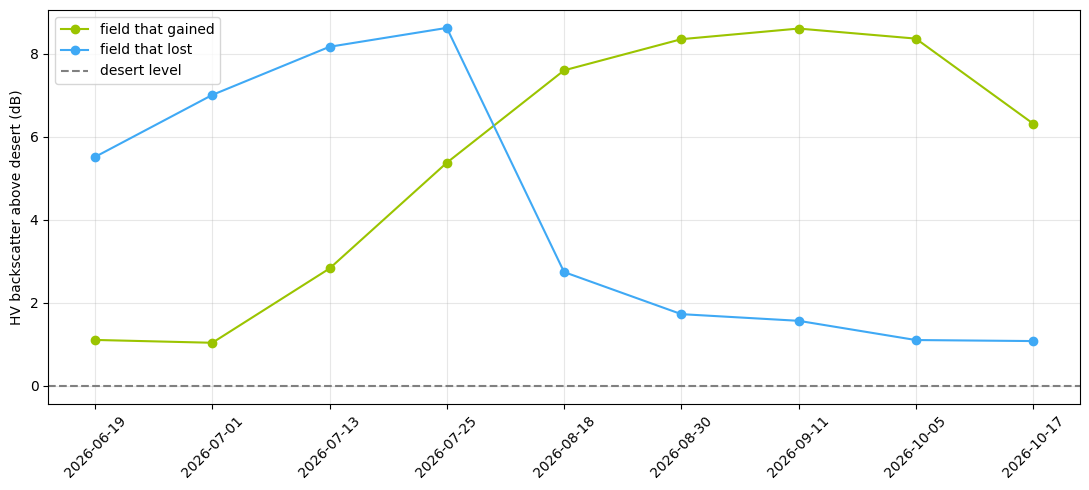

largest drop: -5.9 dB between 2026-07-25 and 2026-08-18
gained field peak: 2026-09-11


In [7]:
def regions(mask, min_px=300):
    m = ndi.binary_opening(mask, iterations=2)
    lab, n = ndi.label(m)
    sizes = np.array(ndi.sum(m, lab, range(1, n + 1)))
    keep = np.where(sizes >= min_px)[0] + 1
    return lab, keep, sizes

lab_g, keep_g, size_g = regions(gain)
lab_l, keep_l, size_l = regions(loss)
print(len(keep_g), "gained fields,", len(keep_l), "lost fields")

def pick(keep, sizes, target=1800):    # closest to one full circle
    return keep[np.argmin(np.abs(sizes[keep - 1] - target))]

mask_g = lab_g == pick(keep_g, size_g)
mask_l = lab_l == pick(keep_l, size_l)
mask_d = np.zeros_like(gain); mask_d[DESERT] = True

def rel_series(mask, ch):
    f = np.array([10 * np.log10(data[d][ch][mask].mean()) for d in dates])
    r = np.array([10 * np.log10(np.median(data[d][ch][mask_d])) for d in dates])
    return f - r

g = rel_series(mask_g, "hv")
l = rel_series(mask_l, "hv")

plt.figure(figsize=(11, 5))
plt.plot(dates, g, "o-", color="#9BC400", label="field that gained")
plt.plot(dates, l, "o-", color="#3FA9F5", label="field that lost")
plt.axhline(0, color="gray", ls="--", label="desert level")
plt.ylabel("HV backscatter above desert (dB)"); plt.xticks(rotation=45)
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("/content/timeline_corrected.png", dpi=150)
plt.show()

i = np.argmin(np.diff(l))
print(f"largest drop: {np.diff(l)[i]:.1f} dB between {dates[i]} and {dates[i+1]}")
print(f"gained field peak: {dates[int(np.argmax(g))]}")

## 8. Two channels: HH (surface) and HV (vegetation)

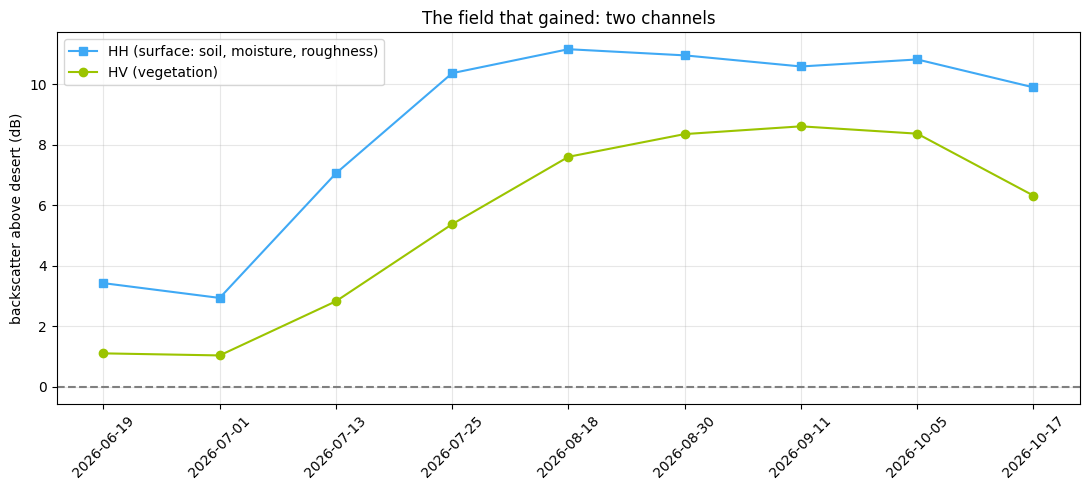

In [8]:
plt.figure(figsize=(11, 5))
plt.plot(dates, rel_series(mask_g, "hh"), "s-", color="#3FA9F5", label="HH (surface: soil, moisture, roughness)")
plt.plot(dates, rel_series(mask_g, "hv"), "o-", color="#9BC400", label="HV (vegetation)")
plt.axhline(0, color="gray", ls="--")
plt.title("The field that gained: two channels")
plt.ylabel("backscatter above desert (dB)"); plt.xticks(rotation=45)
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig("/content/two_channels.png", dpi=150)
plt.show()

## 9. Full-season stacks and building mask

In [9]:
stack_hv = np.stack([to_db(data[d]["hv"]) for d in dates])
stack_hh = np.stack([to_db(data[d]["hh"]) for d in dates])

hh_med = np.median(stack_hh, axis=0)
structures = (hh_med - np.median(hh_med[DESERT])) > 12   # always very bright in HH = buildings

print("stack shape:", stack_hv.shape, stack_hh.shape)
print("valid values:", np.isfinite(stack_hv).all(), np.isfinite(stack_hh).all())
print("structures masked:", round(structures.sum() * px_km2, 2), "km²")

stack shape: (9, 1000, 1000) (9, 1000, 1000)
valid values: True True
structures masked: 2.7 km²


## 10. Active vegetated area per date (4 dB above desert), with 3 and 5 dB sensitivity test

2026-06-19 19.4 km²
2026-07-01 21.0 km²
2026-07-13 22.4 km²
2026-07-25 23.6 km²
2026-08-18 27.1 km²
2026-08-30 27.5 km²
2026-09-11 27.5 km²
2026-10-05 29.1 km²
2026-10-17 26.7 km²
threshold 3 dB: 32.0 km² on 2026-06-19, max 41.9 km²
threshold 5 dB: 13.0 km² on 2026-06-19, max 21.0 km²


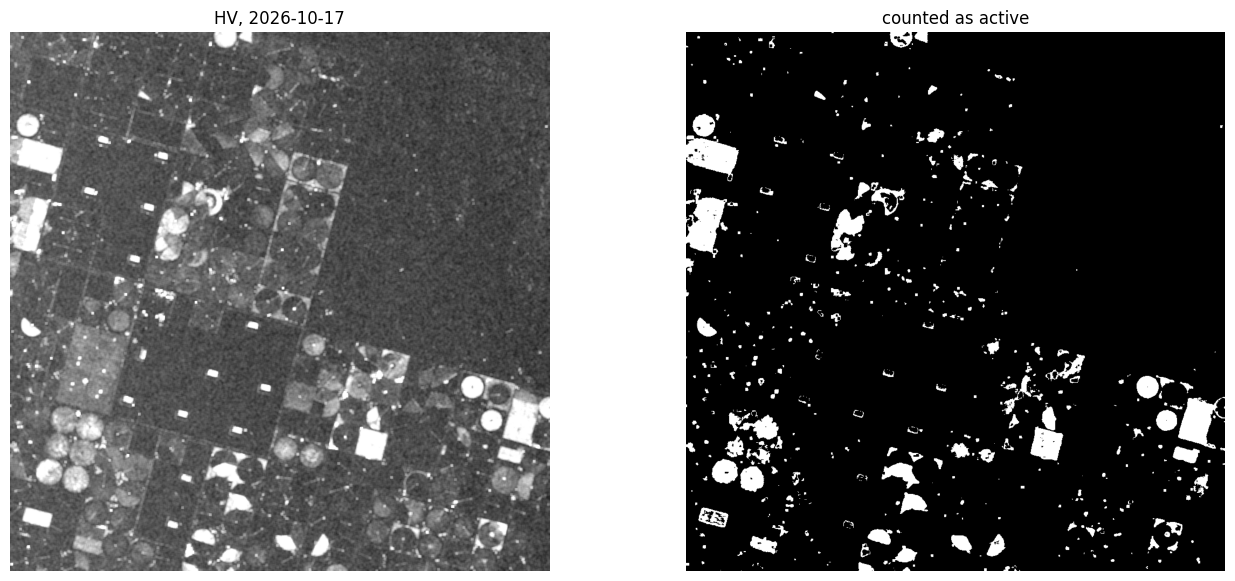

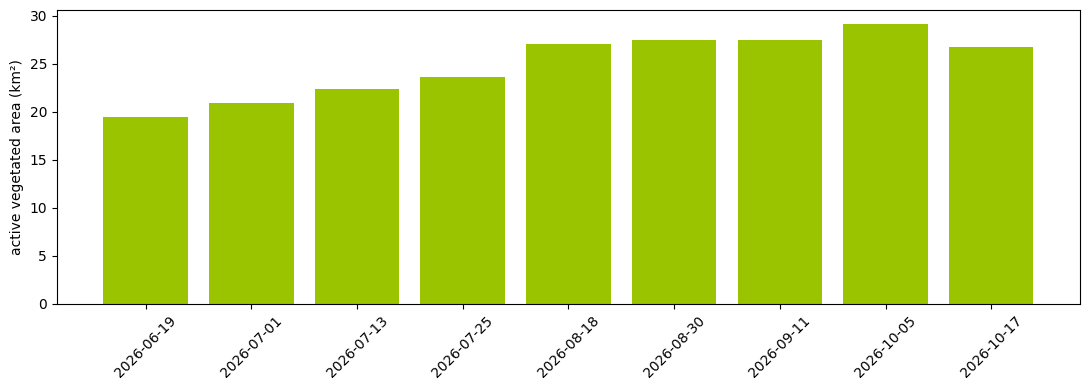

In [10]:
des_med = np.median(stack_hv[:, DESERT[0], DESERT[1]], axis=(1, 2))
rel = stack_hv - des_med[:, None, None]

active = (rel > 4) & ~structures
area = active.sum(axis=(1, 2)) * px_km2
for d, a_ in zip(dates, area):
    print(d, f"{a_:.1f} km²")

for t in (3, 5):
    a_t = ((rel > t) & ~structures).sum(axis=(1, 2)) * px_km2
    print(f"threshold {t} dB: {a_t[0]:.1f} km² on {dates[0]}, max {a_t.max():.1f} km²")

fig, ax = plt.subplots(1, 2, figsize=(16, 7))
ax[0].imshow(stack_hv[-1], cmap="gray", vmin=-26, vmax=-16); ax[0].set_title("HV, " + dates[-1])
ax[1].imshow(active[-1], cmap="gray"); ax[1].set_title("counted as active")
for x in ax: x.axis("off")
plt.show()

plt.figure(figsize=(11, 4))
plt.bar(dates, area, color="#9BC400")
plt.ylabel("active vegetated area (km²)"); plt.xticks(rotation=45)
plt.tight_layout(); plt.savefig("/content/active_area.png", dpi=150); plt.show()

## 11. Automatic circle detection (candidates)


55 candidate circles


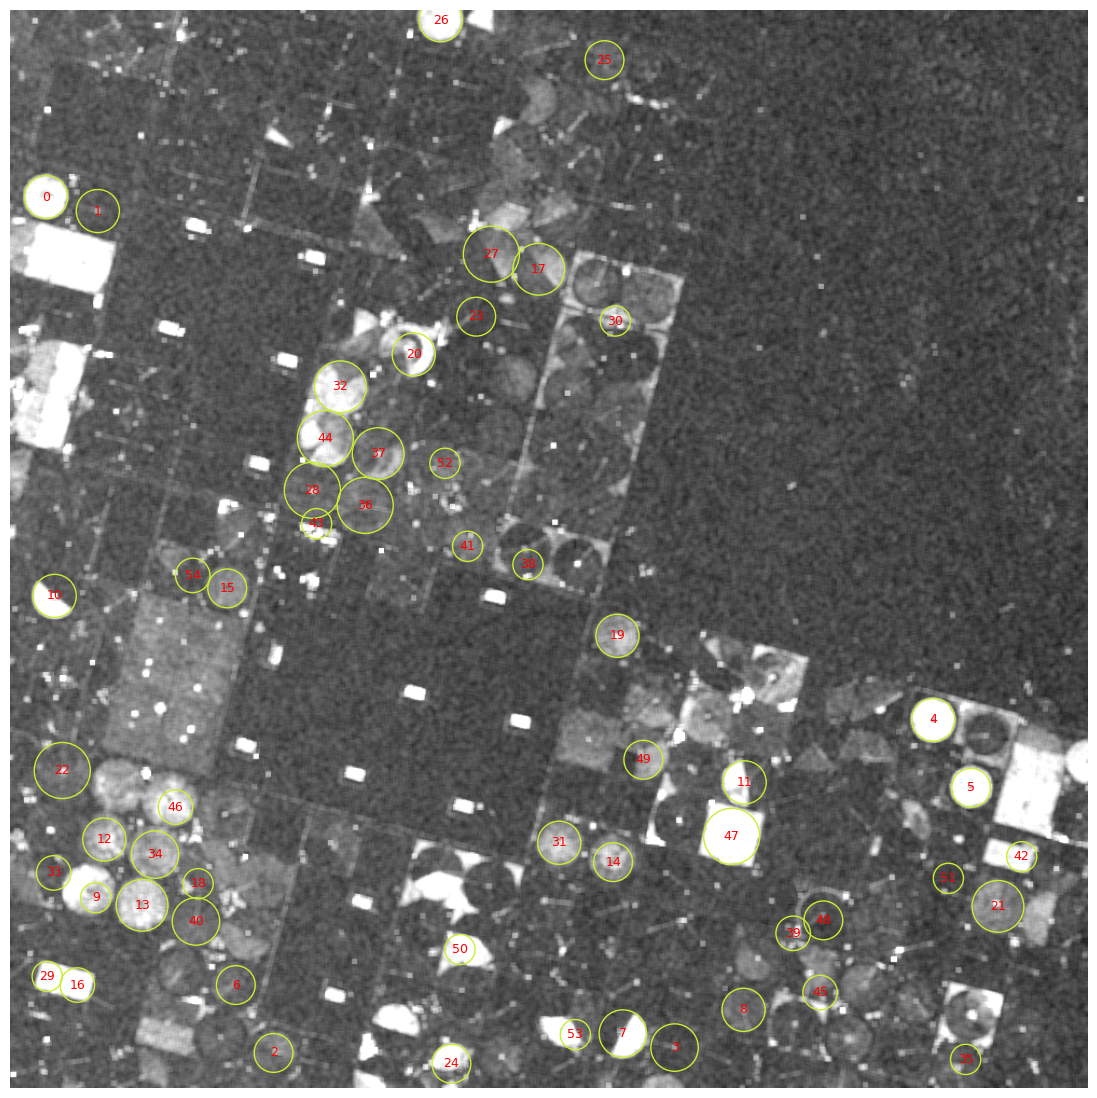

In [11]:
from skimage.feature import canny
from skimage.transform import hough_circle, hough_circle_peaks
from skimage.draw import disk

ever = np.where(structures, 0, rel.max(axis=0))
edges = canny(ever, sigma=3, low_threshold=1, high_threshold=3)

radii = np.arange(14, 31, 2)
hspace = hough_circle(edges, radii)
acc, cx, cy, rr = hough_circle_peaks(hspace, radii, min_xdistance=25,
                                     min_ydistance=25, threshold=0.3,
                                     total_num_peaks=400)

fields = []
for x, y, r in zip(cx, cy, rr):
    yy, xx = disk((y, x), r * 0.8, shape=ever.shape)
    if ever[yy, xx].mean() > 3:
        fields.append((x, y, r, yy, xx))
print(len(fields), "candidate circles")

# numbered map for visual checking
fig, ax = plt.subplots(figsize=(14, 14))
ax.imshow(stack_hv[-1], cmap="gray", vmin=-26, vmax=-16)
for i, (x, y, r, _, _) in enumerate(fields):
    ax.add_patch(plt.Circle((x, y), r, fill=False, color="#C8F031", lw=1))
    ax.text(x, y, str(i), color="red", fontsize=9, ha="center", va="center")
ax.axis("off"); plt.show()

## 12. Confirmed fields only


38 confirmed of 55 candidates
2026-06-19 4 active fields
2026-07-01 6 active fields
2026-07-13 4 active fields
2026-07-25 6 active fields
2026-08-18 10 active fields
2026-08-30 9 active fields
2026-09-11 16 active fields
2026-10-05 17 active fields
2026-10-17 16 active fields


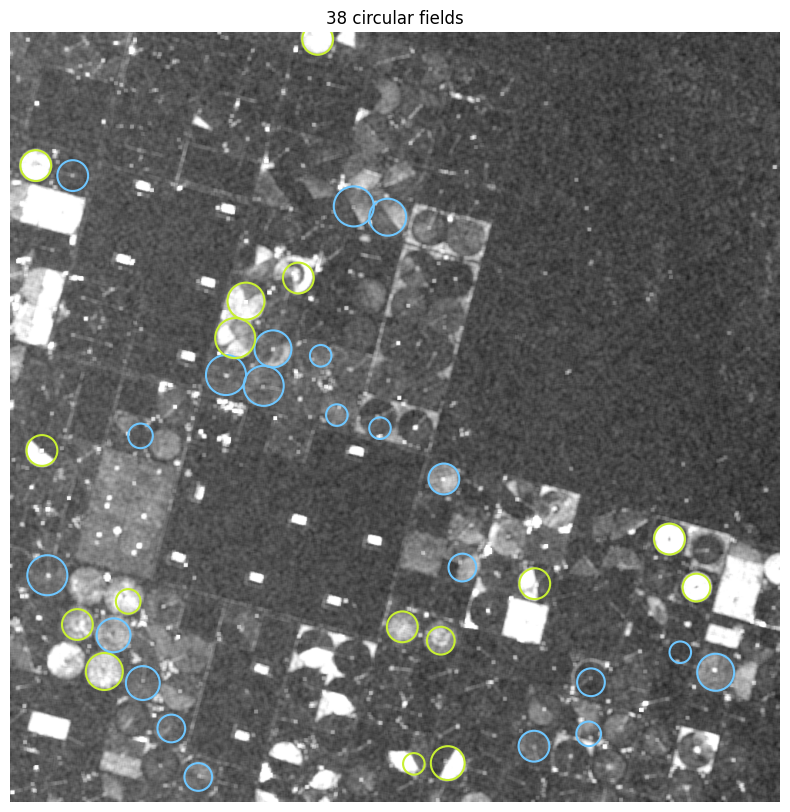

In [14]:
 bad = [3, 9, 15, 16, 18, 23, 24, 25, 29, 30, 33, 35, 39, 42, 43 , 47, 50]   # e.g. [3, 17, 22]

good = [f for i, f in enumerate(fields) if i not in bad]
state = np.array([[rel[i][f[3], f[4]].mean() > 4 for f in good] for i in range(len(dates))])
print(len(good), "confirmed of", len(fields), "candidates")
for d, s in zip(dates, state.sum(axis=1)):
    print(d, s, "active fields")

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(stack_hv[-1], cmap="gray", vmin=-26, vmax=-16)
for (x, y, r, _, _), on in zip(good, state[-1]):
    ax.add_patch(plt.Circle((x, y), r, fill=False, color="#C8F031" if on else "#6EC6FF", lw=1.5))
ax.set_title(f"{len(good)} circular fields")
ax.axis("off")
plt.savefig("/content/fields_detected.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
!pip install -q rasterio
import rasterio
from rasterio.io import MemoryFile
from rasterio.windows import from_bounds, Window
from rasterio.warp import transform_bounds
from rasterio.transform import rowcol
from datetime import datetime

# Same 20 km window as the radar crop, in UTM 37N (EPSG 32637)
t_ll = Transformer.from_crs("EPSG:4326", "EPSG:32637", always_xy=True)
cx_utm, cy_utm = t_ll.transform(FARM_LON, FARM_LAT)
left, top = cx_utm - HALF * 20, cy_utm + HALF * 20
right, bottom = left + 2 * HALF * 20, top - 2 * HALF * 20

def read_window(url):
    with fs.open(url, "rb") as fo:
        buf = fo.read()
    with MemoryFile(buf) as mf, mf.open() as src:
        b = transform_bounds("EPSG:32637", src.crs, left, bottom, right, top)
        w = from_bounds(*b, transform=src.transform)
        w = Window(int(round(w.col_off)), int(round(w.row_off)), int(round(w.width)), int(round(w.height)))
        fill = src.nodata if src.nodata is not None else -9999
        arr = src.read(1, window=w, boundless=True, fill_value=fill)
        return arr, src.window_transform(w), src.crs

hls = earthaccess.search_data(
    short_name=["HLSS30", "HLSL30"],
    bounding_box=(38.35, 30.04, 38.57, 30.24),
    temporal=("2026-06-10", "2026-10-25"),
)
scenes = []
for g in hls:
    links = g.data_links()
    day = g["umm"]["TemporalExtent"]["RangeDateTime"]["BeginningDateTime"][:10]
    sensor = "S30" if any(".S30." in l for l in links) else "L30"
    pick = lambda s: next((l for l in links if l.endswith(s)), None)
    nir = pick(".B8A.tif") if sensor == "S30" else pick(".B05.tif")
    scenes.append({"day": day, "sensor": sensor, "red": pick(".B04.tif"), "nir": nir, "fmask": pick(".Fmask.tif")})
print(len(scenes), "HLS scenes found")

optical = {}
for d in dates:
    dn = datetime.strptime(d, "%Y-%m-%d")
    cands = sorted((s for s in scenes if s["red"] and s["nir"] and s["fmask"]),
                   key=lambda s: abs((datetime.strptime(s["day"], "%Y-%m-%d") - dn).days))
    for s in cands:
        gap = abs((datetime.strptime(s["day"], "%Y-%m-%d") - dn).days)
        if gap > 6:
            break
        fm, T, crs = read_window(s["fmask"])
        good_px = (fm != 255) & ((fm & 0b1110) == 0)     # not fill, not cloud / adjacent / shadow
        frac = good_px.mean()
        if frac < 0.9:
            print(f"{d}: {s['day']} {s['sensor']} rejected ({frac:.0%} clear and inside tile)")
            continue
        red, _, _ = read_window(s["red"])
        nir, _, _ = read_window(s["nir"])
        red = red.astype("float64"); nir = nir.astype("float64")
        ok = good_px & (red > 0) & (nir > 0) & (red != -9999) & (nir != -9999)
        ndvi = np.where(ok, (nir - red) / (nir + red), np.nan)
        optical[d] = {"ndvi": ndvi, "T": T, "crs": crs, "day": s["day"], "sensor": s["sensor"], "gap": gap}
        print(f"{d}: matched {s['day']} {s['sensor']} ({gap} days apart, {frac:.0%} clear)")
        break
    if d not in optical:
        print(f"{d}: no clear optical image within 6 days")
print(len(optical), "of", len(dates), "radar dates matched")

87 HLS scenes found
2026-06-19: matched 2026-06-20 S30 (1 days apart, 100% clear)
2026-07-01: matched 2026-06-30 S30 (1 days apart, 100% clear)
2026-07-13: matched 2026-07-12 S30 (1 days apart, 100% clear)
2026-07-25: matched 2026-07-25 S30 (0 days apart, 100% clear)
2026-08-18: matched 2026-08-18 S30 (0 days apart, 100% clear)
2026-08-30: matched 2026-08-29 S30 (1 days apart, 100% clear)
2026-09-11: matched 2026-09-10 S30 (1 days apart, 100% clear)
2026-10-05: matched 2026-10-05 S30 (0 days apart, 100% clear)
2026-10-17: matched 2026-10-17 S30 (0 days apart, 100% clear)
9 of 9 radar dates matched


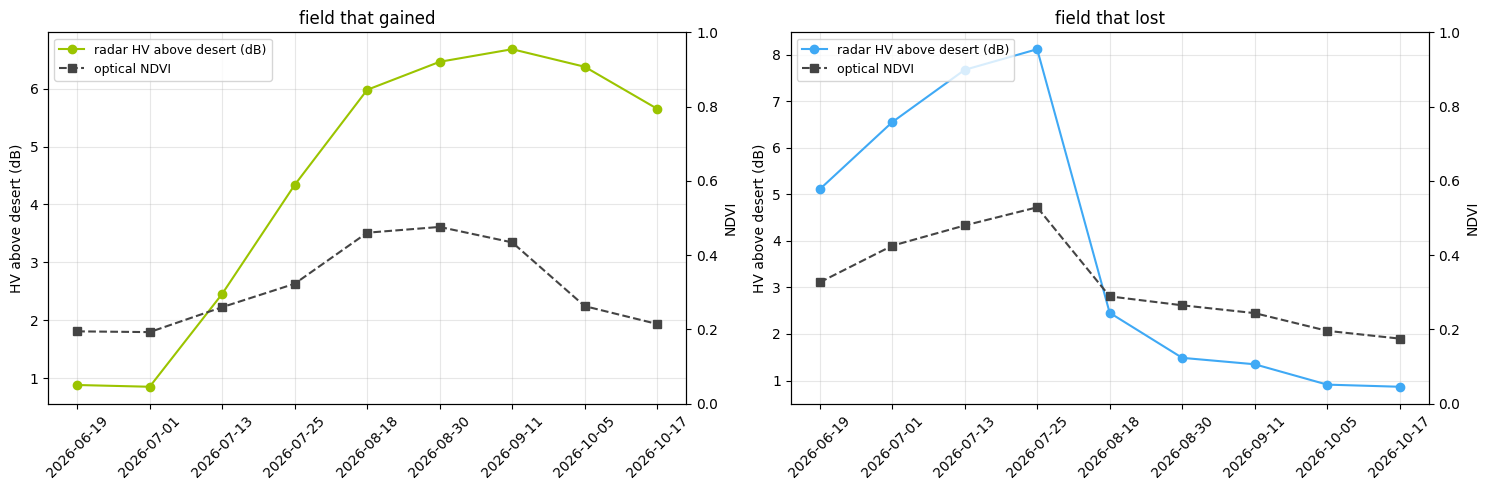

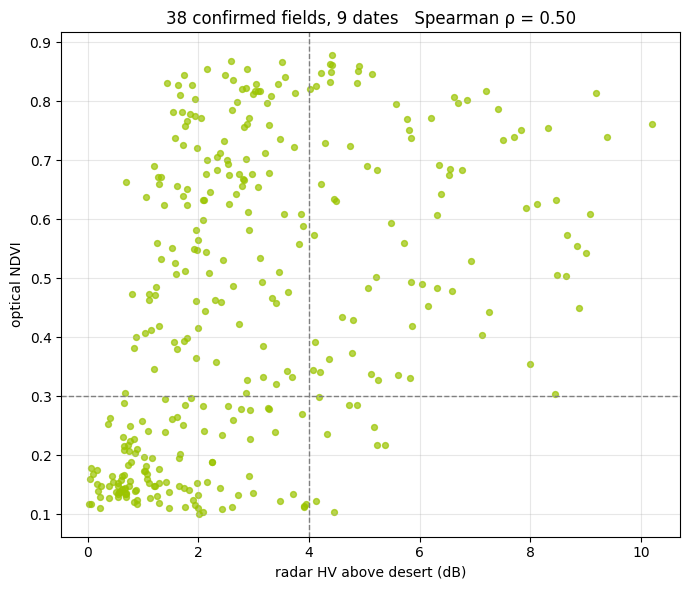

field-date pairs compared: 342
Spearman correlation, radar HV vs NDVI: 0.50 (p = 5.6e-23)
agreement on active/inactive (HV > 4 dB vs NDVI > 0.3): 58%
field that gained NDVI: [0.19 0.19 0.26 0.32 0.46 0.48 0.43 0.26 0.21]
field that lost NDVI: [0.33 0.43 0.48 0.53 0.29 0.26 0.24 0.2  0.18]


In [16]:
from scipy.stats import spearmanr

def px_to_utm(col, row):
    return left + (np.asarray(col) + 0.5) * 20, top - (np.asarray(row) + 0.5) * 20

targets = [{"name": f"field {k}", "rc": (f[3], f[4])} for k, f in enumerate(good)]
for name, m in [("field that gained", mask_g), ("field that lost", mask_l)]:
    targets.append({"name": name, "rc": np.nonzero(m)})

def field_ndvi(rc, o):
    X, Y = px_to_utm(rc[1], rc[0])
    if str(o["crs"]) != "EPSG:32637":
        X, Y = Transformer.from_crs("EPSG:32637", o["crs"], always_xy=True).transform(X, Y)
    r, c = rowcol(o["T"], X, Y)
    r, c = np.asarray(r), np.asarray(c)
    inside = (r >= 0) & (r < o["ndvi"].shape[0]) & (c >= 0) & (c < o["ndvi"].shape[1])
    v = o["ndvi"][r[inside], c[inside]]
    return np.nan if np.isfinite(v).sum() < 10 else np.nanmean(v)

mdates = [d for d in dates if d in optical]
for t in targets:
    t["hv"] = np.array([rel[dates.index(d)][t["rc"]].mean() for d in mdates])
    t["ndvi"] = np.array([field_ndvi(t["rc"], optical[d]) for d in mdates])

# 1) the two example fields: radar and optical side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, t, col in zip(axes, targets[-2:], ["#9BC400", "#3FA9F5"]):
    ax.plot(mdates, t["hv"], "o-", color=col, label="radar HV above desert (dB)")
    ax.set_ylabel("HV above desert (dB)"); ax.tick_params(axis="x", rotation=45)
    ax2 = ax.twinx()
    ax2.plot(mdates, t["ndvi"], "s--", color="#444444", label="optical NDVI")
    ax2.set_ylabel("NDVI"); ax2.set_ylim(0, 1)
    ax.set_title(t["name"]); ax.grid(alpha=0.3)
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=9)
plt.tight_layout(); plt.savefig("/content/ndvi_validation.png", dpi=150); plt.show()

# 2) every confirmed field on every matched date
hv_all = np.concatenate([t["hv"] for t in targets[:-2]])
nd_all = np.concatenate([t["ndvi"] for t in targets[:-2]])
ok = np.isfinite(hv_all) & np.isfinite(nd_all)
rho, p = spearmanr(hv_all[ok], nd_all[ok])
agree = ((hv_all[ok] > 4) == (nd_all[ok] > 0.3)).mean()

plt.figure(figsize=(7, 6))
plt.scatter(hv_all[ok], nd_all[ok], s=18, color="#9BC400", alpha=0.7)
plt.axvline(4, color="gray", ls="--", lw=1); plt.axhline(0.3, color="gray", ls="--", lw=1)
plt.xlabel("radar HV above desert (dB)"); plt.ylabel("optical NDVI")
plt.title(f"{len(targets) - 2} confirmed fields, {len(mdates)} dates   Spearman ρ = {rho:.2f}")
plt.grid(alpha=0.3); plt.tight_layout(); plt.savefig("/content/ndvi_scatter.png", dpi=150); plt.show()

print(f"field-date pairs compared: {ok.sum()}")
print(f"Spearman correlation, radar HV vs NDVI: {rho:.2f} (p = {p:.1e})")
print(f"agreement on active/inactive (HV > 4 dB vs NDVI > 0.3): {agree:.0%}")
for t in targets[-2:]:
    print(t["name"], "NDVI:", np.round(t["ndvi"], 2))

## 13. Export images, animation and download

In [17]:
from PIL import Image, ImageDraw, ImageFont
from google.colab import files

try:
    font = ImageFont.load_default(size=42)
except TypeError:
    font = ImageFont.load_default()

frames = []
for i, d in enumerate(dates):
    g8 = (np.clip((stack_hv[i] + 26) / 10, 0, 1) * 255).astype("uint8")
    im = Image.fromarray(g8).convert("RGB")
    im.save(f"/content/hv_{d}.png")
    ImageDraw.Draw(im).text((24, 20), d, fill=(200, 240, 49), font=font)
    frames.append(im)
frames[0].save("/content/echofield_season.gif", save_all=True,
               append_images=frames[1:], duration=800, loop=0)

plt.imsave("/content/change.png", corrected, cmap=echo, vmin=-6, vmax=6)

with zipfile.ZipFile("/content/echofield_assets.zip", "w") as zf:
    for p in glob.glob("/content/*.png") + glob.glob("/content/*.gif"):
        zf.write(p, p.split("/")[-1])
files.download("/content/echofield_assets.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>